# 03 - ADMIXTURE: model-based soft clustering

K-means assigns every person to exactly one cluster. ADMIXTURE instead models
each person as a **mixture** of K ancestral populations:

$$ p_{ij} = \sum_{k=1}^{K} q_{ik} f_{kj} $$

where $p_{ij}$ is the frequency of the variant allele at SNP $j$ for person
$i$, $q_{ik}$ is the proportion of ancestry component $k$ in person $i$, and
$f_{kj}$ is the allele frequency of SNP $j$ in component $k$. The $q$ values
are estimated by maximum likelihood under Hardy-Weinberg equilibrium within
each component, treating SNPs as unlinked.

This notebook:

1. explains the model and the meaning of the `Q` matrix,
2. fits K = 2..7 on a West Eurasian panel (cached by
   `scripts/05_admixture_panel.sh`), and
3. shows the classic failure modes: choosing K, and **label switching**.

In [1]:
from pathlib import Path
import re
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import poreklo_io as pio

FIG = ROOT / "results" / "figures"
NB03 = ROOT / "data" / "processed" / "nb03"
meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
group_of = dict(zip(meta["iid"], meta["group"]))
balkan = {"Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"}

# Build the panel and run the K sweep; cached after the first run.
if not (NB03 / "panel.7.s42.Q").exists():
    result = subprocess.run(["bash", str(ROOT / "scripts" / "05_admixture_panel.sh")],
                            cwd=ROOT, capture_output=True, text=True)
    print(result.stdout[-3000:])
    if result.returncode:
        print(result.stderr[-3000:])
        raise RuntimeError("ADMIXTURE run failed")

fam = pio.read_fam(str(NB03 / "panel.fam"))
iids = [s["iid"] for s in fam]
print(f"panel: {len(iids)} samples, {sum(1 for _ in open(NB03 / 'panel.bim')):,} SNPs")

panel: 509 samples, 59,278 SNPs


## Choosing K with cross-validation

ADMIXTURE's `--cv` hides a fraction of genotypes, predicts them from the
fitted model, and reports the prediction error for each K. The minimum is a
*heuristic*: it tells you which K predicts held-out genotypes best, not which
K is "biologically true". Human data often keeps improving slowly with K,
without a clear elbow, because populations are nested and clinal.

{2: 0.5779, 3: 0.5793, 4: 0.5834, 5: 0.5935, 6: 0.6008, 7: 0.5995}


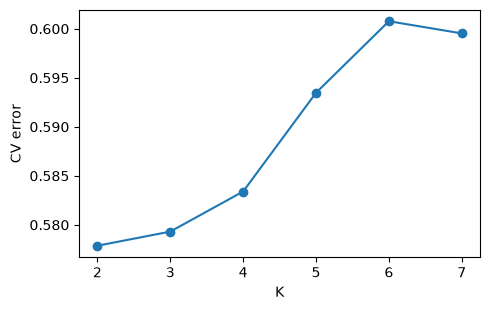

In [2]:
cv = {}
for k in range(2, 8):
    text = (NB03 / f"log.{k}.s42.txt").read_text()
    match = re.search(r"CV error \(K=(\d+)\): *([0-9.]+)", text)
    cv[k] = float(match.group(2))
cv_series = pd.Series(cv)
print(cv_series.round(4).to_dict())
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(cv_series.index, cv_series.values, marker="o")
ax.set_xlabel("K"); ax.set_ylabel("CV error")
fig.tight_layout(); fig.savefig(FIG / "nb03_cv_error.png", dpi=130); plt.show()

## Q matrices and label switching

The output `panel.K.Q` has one row per sample and K columns of ancestry
proportions. ADMIXTURE does not order the columns: two runs with different
seeds can produce the *same* solution with columns permuted ("label
switching"). Always align runs before comparing or averaging them.

Below: K = 3 fitted with seeds 42, 1 and 2. The correlation matrices show
that matching columns across seeds requires a permutation, not just the
identity mapping.

In [3]:
def load_q(k, seed=42):
    q = pd.read_csv(NB03 / f"panel.{k}.s{seed}.Q", sep=r"\s+", header=None)
    q.index = iids
    return q

q42, q1, q2 = load_q(3, 42), load_q(3, 1), load_q(3, 2)
corr = np.corrcoef(np.hstack([q42, q1]), rowvar=False)[:3, 3:]
rows, cols = linear_sum_assignment(-corr)
print("correlation between seed 42 and seed 1 columns:\n", np.round(corr, 3))
print("best matching permutation:", dict(zip(range(3), cols)))
print("mean |Q difference| aligned:", float(np.abs(q42.values - q1.values[:, cols]).mean()))

correlation between seed 42 and seed 1 columns:
 [[-0.675  0.645  0.364]
 [ 0.997 -0.754 -0.749]
 [-0.744  0.451  0.677]]
best matching permutation: {0: np.int64(1), 1: np.int64(0), 2: np.int64(2)}
mean |Q difference| aligned: 0.06624001309757695


## Reading the fitted components

The stacked barplots below show one row per person, one colour per component,
for K = 3, 5 and 7. Samples are grouped by population label and sorted inside
each group by their largest component.

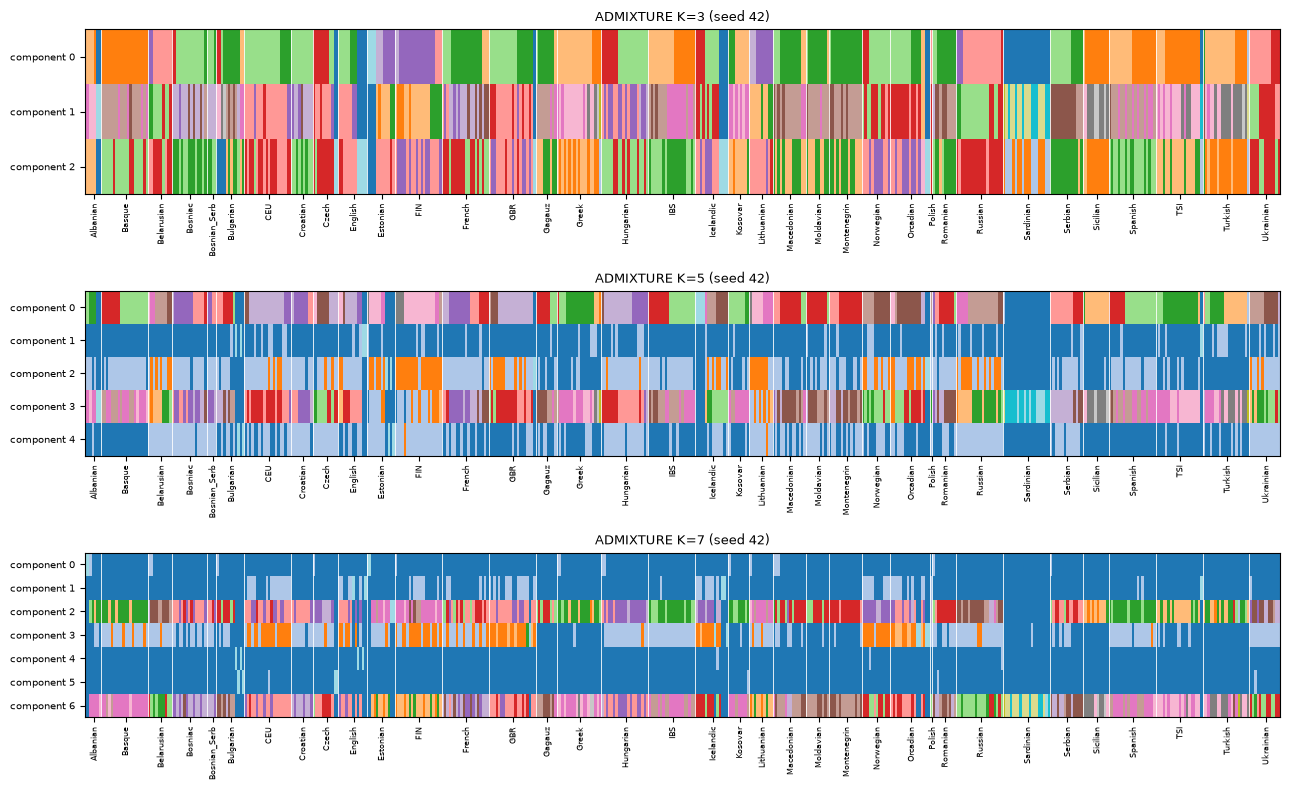

In [4]:
def stacked_barplot(k, seed=42, ax=None, only=None):
    q = load_q(k, seed)
    q["group"] = [group_of[i] for i in q.index]
    q["iid"] = q.index
    if only is not None:
        q = q[q["group"].isin(only)]
    order = []
    for group, sub in q.groupby("group"):
        sub = sub.sort_values(by=list(range(k))[0], ascending=False)
        order += list(sub.index)
    q = q.loc[order]
    ax.imshow(q[list(range(k))].values.T, aspect="auto", cmap="tab20", vmin=0, vmax=1,
              interpolation="nearest")
    positions = np.cumsum([0] + q.groupby("group", sort=False).size().tolist())
    for p in positions[1:-1]:
        ax.axvline(p - 0.5, color="white", lw=0.6)
    ax.set_yticks(range(k)); ax.set_yticklabels([f"component {i}" for i in range(k)], fontsize=7)
    labels = q.groupby("group", sort=False).size().index
    mid = (positions[:-1] + positions[1:]) / 2
    ax.set_xticks(mid); ax.set_xticklabels(labels, rotation=90, fontsize=6)
    ax.set_title(f"ADMIXTURE K={k} (seed {seed})", fontsize=9)

fig, axes = plt.subplots(3, 1, figsize=(13, 8))
for ax, k in zip(axes, [3, 5, 7]):
    stacked_barplot(k, ax=ax)
fig.tight_layout(); fig.savefig(FIG / "nb03_admixture_all.png", dpi=130); plt.show()

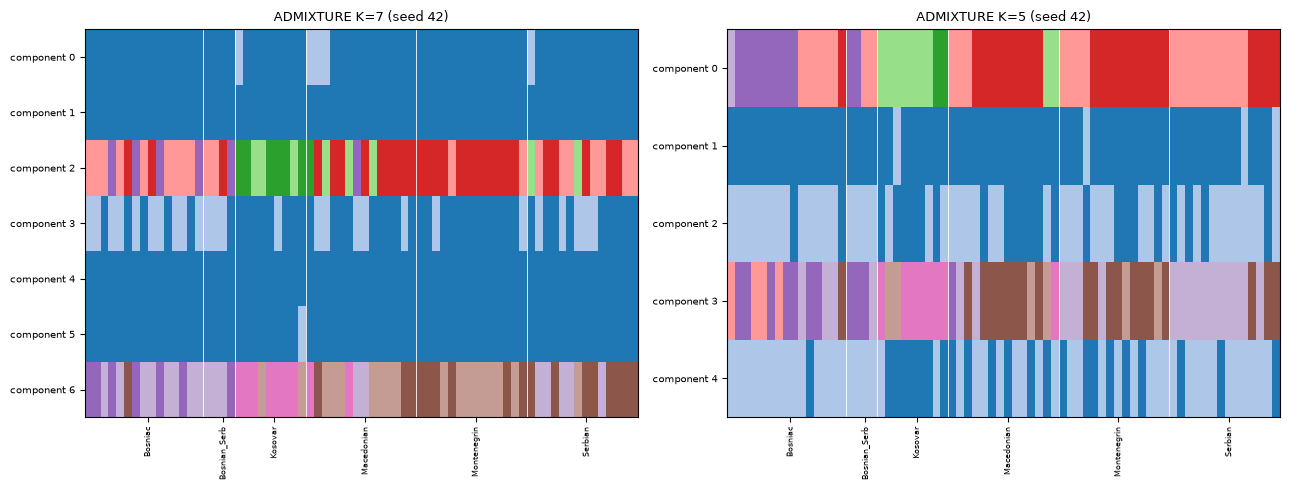

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stacked_barplot(7, ax=axes[0], only=balkan)
stacked_barplot(5, ax=axes[1], only=balkan)
fig.tight_layout(); fig.savefig(FIG / "nb03_admixture_balkans.png", dpi=130); plt.show()

### What to look for (and what not to conclude)

- At low K, all western Balkan samples look alike: they share the same
  European / Mediterranean components. Nation labels do not split them.
- Differences that do appear follow geography (a north-west to south-east
  gradient, Kosovars at one end), not language or religion.
- The number of components is a modelling choice. Running ADMIXTURE until
  "my nation appears" is data dredging; the correct question is predictive
  (notebook 06), not "at which K do I see what I want".

Also note: components are not "ancestral peoples". A component is a set of
correlated allele frequencies; it can correspond to a real historical
population, to a geographic gradient, or to both.

## Exercises

1. Re-run K = 7 with a different seed (edit the script, remove the cached
   files) and align the two Q matrices. How similar are they (mean absolute
   difference after alignment)?
2. Remove the reference panel and run ADMIXTURE on the 70 GEO samples only
   (`--keep` the GEO samples). Which K levels look stable? How do the
   components change meaning without references?
3. Bootstrap: subsample 80% of SNPs and refit K = 5. How much do individual
   ancestry proportions move? This is the uncertainty ADMIXTURE does not
   report by default.

Next: `04_fst_amova.ipynb` quantifies differentiation between groups.